# Notebook 03b · Évaluation unique sur le test 2024-2026

Ce notebook ne choisit **rien**. Il charge la décision figée dans `runs/decision_finale.json` (commit `75712cf`, antérieur à toute évaluation sur le test) et l'applique une fois aux 33 mois du test, de janvier 2024 à septembre 2026.

**Engagement pris avant ce calcul (notebook 03).** Si le modèle perd aussi contre la constante sur le test, la recommandation finale sera « toujours acheter, couvert ».

| Section | Contenu | Cours |
|---|---|---|
| 1 | Probabilités du test : log-loss, Brier, ECE, PR-AUC, reliability diagram | S2, S7, S8 |
| 2 | TP, FP, FN, TN, precision, recall, F1 selon le seuil | S7, S9 |
| 3 | Mêmes métriques pour les trois modèles | exigence 4 |
| 4 | Règle de décision : actions et rendement en euros | S1 ; hors cours pour les euros |
| 5 | Couverture | |
| 6 | Verdict et signal de novembre 2026 | |

In [1]:
from pathlib import Path
import json
import subprocess
import warnings
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import average_precision_score, brier_score_loss, confusion_matrix, log_loss

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "config.yaml"))
FIG, RUNS = ROOT / "figures", ROOT / "runs"
COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

DEC = json.loads((RUNS / "decision_finale.json").read_text())
table = pd.read_csv(ROOT / CFG["data"]["model_table"], parse_dates=["date"]).set_index("date")
FEATURES = [c for g in ["news", "price", "macro", "fx"] for c in CFG["features"][g]]
COLONNES = FEATURES + [c for c in CFG["features"]["regime"] if c not in FEATURES]
train = table[table["bloc"] == "entraînement"]
test = table[table["bloc"] == "test"]
a_predire = table[table["bloc"] == "à prédire"]
MODELES = ["logit", "rf", "lgbm"]
NOMS = {"logit": "logistique", "rf": "Random Forest", "lgbm": "LightGBM"}
PIPES = {m: joblib.load(ROOT / DEC["fichiers_modeles"][m]) for m in MODELES}

print(f"décision figée au commit {DEC['commit_du_code']} le {DEC['date']} ; code exécuté au commit {COMMIT}")
print(f"modèle : {NOMS[DEC['modele_nikkei']]} | marge {100 * DEC['marge_m']:.2f} %/mois | "
      f"θ_v = {DEC['seuils']['theta_v']:.3f}, θ_a = {DEC['seuils']['theta_a']:.3f} | couverture : {DEC['couverture']}")
print(f"test : {len(test)} mois ({test.index[0]:%Y-%m} → {test.index[-1]:%Y-%m}), {int(test['y_baisse'].sum())} baisses")

décision figée au commit 2aa4b40 le 2026-11-11 18:08 ; code exécuté au commit 75712cf
modèle : logistique | marge 0.50 %/mois | θ_v = 0.456, θ_a = 0.580 | couverture : toujours couvert (h = 1)
test : 33 mois (2024-01 → 2026-09), 12 baisses


In [2]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def platt(p, m):
    return 1 / (1 + np.exp(-(DEC["platt"][m]["a"] * logit(p) + DEC["platt"][m]["c"])))

def fiabilite(y, p, M=5):
    groupes = pd.qcut(pd.Series(p).rank(method="first"), q=M, labels=False)
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "g": groupes.values})
    return d.groupby("g").agg(conf=("p", "mean"), acc=("y", "mean"), n=("y", "size"))

def ece(y, p, M=5):
    t = fiabilite(y, p, M)
    return float((t["n"] / t["n"].sum() * (t["acc"] - t["conf"]).abs()).sum())

def scores(y, p):
    return {"log-loss": log_loss(y, p, labels=[0, 1]), "Brier": brier_score_loss(y, p), "ECE": ece(y, p),
            "PR-AUC": average_precision_score(y, p), "proba moyenne": float(np.mean(p)), "fréquence observée": float(np.mean(y))}

y_te = test["y_baisse"].astype(int)
P_te = pd.DataFrame({m: platt(PIPES[m].predict_proba(test[COLONNES])[:, 1], m) for m in MODELES}, index=test.index)
p_const = train["y_baisse"].mean()

## 1. Les probabilités tiennent-elles sur le test ? (S2, S7, S8)

P(baisse) calibrée par Platt, avec les paramètres appris hors fold (notebook 03). La référence est le modèle constant, qui annonce la fréquence de l'entraînement (0,392).

,log-loss,Brier,ECE,PR-AUC,proba moyenne,fréquence observée
logistique,0.708,0.257,0.183,0.420,0.523,0.364
Random Forest,0.788,0.286,0.243,0.388,0.524,0.364
LightGBM,0.751,0.270,0.219,0.416,0.486,0.364
constante (fréquence de l'entraînement),0.657,0.232,0.144,0.364,0.392,0.364


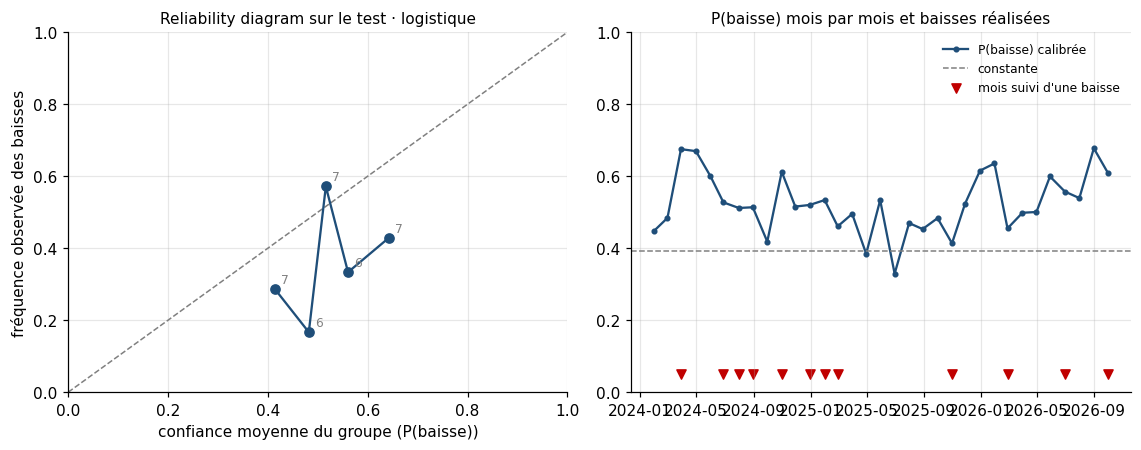

In [3]:
RES = pd.DataFrame({NOMS[m]: scores(y_te, P_te[m]) for m in MODELES}).T
RES.loc["constante (fréquence de l'entraînement)"] = scores(y_te, np.full(len(y_te), p_const))
display(RES.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax = axes[0]
ax.plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
t = fiabilite(y_te, P_te[DEC["modele_nikkei"]])
ax.plot(t["conf"], t["acc"], marker="o", color="#1f4e79")
for _, r in t.iterrows():
    ax.annotate(f"{int(r['n'])}", (r["conf"], r["acc"]), textcoords="offset points", xytext=(4, 4), fontsize=8, color="grey")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("confiance moyenne du groupe (P(baisse))"); ax.set_ylabel("fréquence observée des baisses")
ax.set_title(f"Reliability diagram sur le test · {NOMS[DEC['modele_nikkei']]}", fontsize=10)

ax = axes[1]
ax.plot(test.index, P_te[DEC["modele_nikkei"]], color="#1f4e79", marker="o", ms=3, label="P(baisse) calibrée")
ax.axhline(p_const, color="grey", ls="--", lw=1, label="constante")
baisses = test.index[y_te == 1]
ax.scatter(baisses, np.full(len(baisses), 0.05), marker="v", color="#c00000", label="mois suivi d'une baisse")
ax.set_ylim(0, 1)
ax.set_title("P(baisse) mois par mois et baisses réalisées", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "03b_test_probabilites.png")
plt.show()

## 2. TP, FP, FN, precision, recall et F1 selon le seuil (S7, S9)

Le tableau est descriptif : aucun seuil n'est choisi ici. La classe positive est la baisse. La référence « toujours baisse » a un F1 de 2π/(1 + π), avec π la part de baisses du test.

In [4]:
def tableau_seuils(y, p, seuils=np.round(np.arange(0.30, 0.71, 0.05), 2)):
    lignes = []
    for tau in seuils:
        yhat = (np.asarray(p) >= tau).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        f1 = 2 * prec * rec / (prec + rec) if tp else 0.0
        lignes.append({"seuil τ": tau, "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                       "precision": prec, "recall": rec, "F1": f1, "accuracy": (tp + tn) / len(y)})
    return pd.DataFrame(lignes).set_index("seuil τ")

pi = y_te.mean()
print(f"référence « toujours baisse » sur le test : F1 = {2 * pi / (1 + pi):.3f} ; « toujours hausse » : accuracy = {1 - pi:.3f}, F1 = 0")
tableau_seuils(y_te, P_te[DEC["modele_nikkei"]]).round(3)

référence « toujours baisse » sur le test : F1 = 0.533 ; « toujours hausse » : accuracy = 0.636, F1 = 0


,TP,FP,FN,TN,precision,recall,F1,accuracy
seuil τ,,,,,,,,
0.30,12,21,0,0,0.364,1.000,0.533,0.364
0.35,12,20,0,1,0.375,1.000,0.545,0.394
0.40,12,19,0,2,0.387,1.000,0.558,0.424
0.45,11,17,1,4,0.393,0.917,0.550,0.455
0.50,9,11,3,10,0.450,0.750,0.563,0.576
0.55,4,6,8,15,0.400,0.333,0.364,0.576
0.60,3,5,9,16,0.375,0.250,0.300,0.576
0.65,1,2,11,19,0.333,0.083,0.133,0.606
0.70,0,0,12,21,NaN,0.000,0.000,0.636


## 3. Mêmes métriques pour les trois modèles (exigence 4)

Pour information seulement : le choix du modèle a été figé au notebook 03 et ne change pas ici. Les seuils de comparaison sont 0,5 et la part de baisses de l'entraînement (0,392).

In [5]:
lignes = []
for m in MODELES:
    t = tableau_seuils(y_te, P_te[m], seuils=[0.392, 0.5])
    for tau, r in t.iterrows():
        lignes.append({"modèle": NOMS[m], "seuil τ": tau, **r[["TP", "FP", "FN", "TN", "precision", "recall", "F1"]].to_dict()})
pd.DataFrame(lignes).set_index(["modèle", "seuil τ"]).round(3)

TP    FP   FN    TN  precision  recall     F1
modèle        seuil τ                                                 
logistique    0.392    12.0  19.0  0.0   2.0      0.387   1.000  0.558
              0.500     9.0  11.0  3.0  10.0      0.450   0.750  0.563
Random Forest 0.392     9.0  17.0  3.0   4.0      0.346   0.750  0.474
              0.500     8.0  10.0  4.0  11.0      0.444   0.667  0.533
LightGBM      0.392    10.0  13.0  2.0   8.0      0.435   0.833  0.571
              0.500     6.0   9.0  6.0  12.0      0.400   0.500  0.444

## 4. La règle de décision sur le test

Les seuils θ<sub>v</sub> et θ<sub>a</sub> s'appliquent à la probabilité calibrée de **hausse**, p<sub>t</sub> = 1 − P(baisse). On achète couvert si p<sub>t</sub> ≥ θ<sub>a</sub>, on vend si p<sub>t</sub> ≤ θ<sub>v</sub>, sinon on reste neutre.

Les références : toujours acheter (couvert ou non), toujours neutre, et la même exposition moyenne que la règle sans aucun timing. Cette dernière est la référence honnête : elle dit si le *moment* des décisions a rapporté quelque chose.

In [6]:
K = DEC["couts_entrainement_exces_du_cash"]

def actions(p_hausse, m=DEC["marge_m"]):
    gain_achat = p_hausse * K["B_u"] + (1 - p_hausse) * K["B_d"]
    gain_vente = p_hausse * K["S_u"] + (1 - p_hausse) * K["S_d"]
    meilleur = np.where(gain_achat >= gain_vente, "acheter", "vendre")
    return pd.Series(np.where(np.maximum(gain_achat, gain_vente) >= m, meilleur, "neutre"), index=p_hausse.index)

def rendements(act, bloc):
    cash = bloc["eur_overnight"] / 100 / 12
    return pd.Series(np.select([act == "acheter", act == "vendre"],
                               [bloc["target_reur_hedged_next"], bloc["target_short_eur_next"]], cash), index=bloc.index)

def perf(r):
    w = np.cumprod(1 + np.asarray(r))
    n = len(w)
    return {"cumul": w[-1] - 1, "annualisé": w[-1] ** (12 / n) - 1, "perte maximale": float(np.min(w / np.maximum.accumulate(w)) - 1)}

p_hausse_te = 1 - P_te[DEC["modele_nikkei"]]
ACT = actions(p_hausse_te)
R_regle = rendements(ACT, test)
cash_te = test["eur_overnight"] / 100 / 12
expo = ACT.map({"acheter": 1, "neutre": 0, "vendre": -1}).mean()
R_expo = cash_te + expo * (test["target_reur_hedged_next"] - cash_te)

PERF = pd.DataFrame({
    "règle du modèle": perf(R_regle),
    "toujours acheter, couvert": perf(test["target_reur_hedged_next"]),
    "toujours acheter, non couvert": perf(test["target_reur_unhedged_next"]),
    "toujours neutre (cash)": perf(cash_te),
    f"même exposition moyenne ({expo:.0%}), sans timing": perf(R_expo),
}).T
print(f"actions sur le test : {ACT.value_counts().to_dict()}")
PERF.round(3)

actions sur le test : {'neutre': 19, 'vendre': 10, 'acheter': 4}


,cumul,annualisé,perte maximale
règle du modèle,0.035,0.013,-0.230
"toujours acheter, couvert",0.823,0.244,-0.132
"toujours acheter, non couvert",0.579,0.181,-0.128
toujours neutre (cash),0.076,0.027,0.000
"même exposition moyenne (-18%), sans timing",-0.037,-0.014,-0.101


y_baisse,hausse réalisée,baisse réalisée
row_0,,
acheter,3,1
neutre,12,7
vendre,6,4


precision de « acheter » : 0.75 | precision de « vendre » : 0.40 | recall des baisses évitées : 0.92


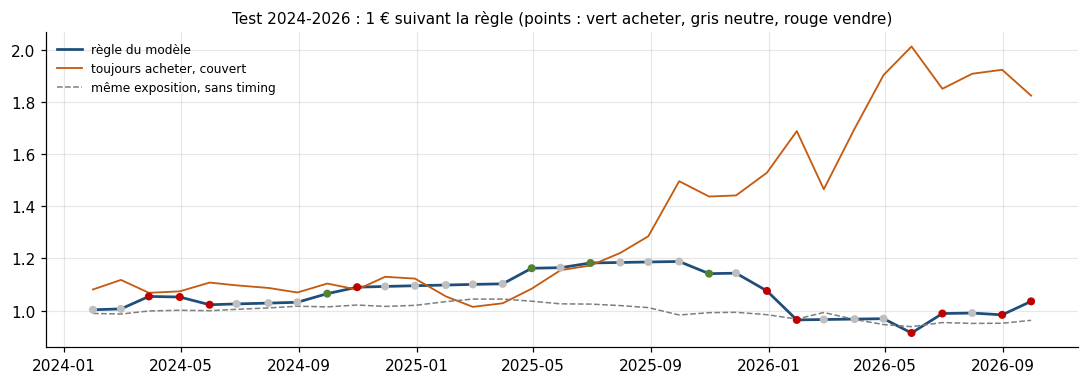

In [7]:
croise = pd.crosstab(ACT, y_te.map({0: "hausse réalisée", 1: "baisse réalisée"})).reindex(["acheter", "neutre", "vendre"], fill_value=0)
croise = croise.reindex(columns=["hausse réalisée", "baisse réalisée"], fill_value=0)
display(croise)
n = croise
prec_achat = n.loc["acheter", "hausse réalisée"] / n.loc["acheter"].sum() if n.loc["acheter"].sum() else np.nan
prec_vente = n.loc["vendre", "baisse réalisée"] / n.loc["vendre"].sum() if n.loc["vendre"].sum() else np.nan
recall_evite = (n.loc["neutre", "baisse réalisée"] + n.loc["vendre", "baisse réalisée"]) / n["baisse réalisée"].sum()
print(f"precision de « acheter » : {prec_achat:.2f} | precision de « vendre » : {prec_vente:.2f} | "
      f"recall des baisses évitées : {recall_evite:.2f}")

fig, ax = plt.subplots(figsize=(10, 3.6))
w = np.cumprod(1 + R_regle)
ax.plot(test.index, w, color="#1f4e79", lw=1.8, label="règle du modèle")
ax.plot(test.index, np.cumprod(1 + test["target_reur_hedged_next"]), color="#c55a11", lw=1.2, label="toujours acheter, couvert")
ax.plot(test.index, np.cumprod(1 + R_expo), color="#7f7f7f", lw=1, ls="--", label="même exposition, sans timing")
couleur = {"acheter": "#548235", "neutre": "#bfbfbf", "vendre": "#c00000"}
ax.scatter(test.index, w, c=[couleur[a] for a in ACT], s=18, zorder=3)
ax.set_title("Test 2024-2026 : 1 € suivant la règle (points : vert acheter, gris neutre, rouge vendre)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "03b_test_regle.png")
plt.show()

## 5. Couverture : « toujours couvert » sur le test

In [8]:
couv = pd.DataFrame({"couvert": perf(test["target_reur_hedged_next"]), "non couvert": perf(test["target_reur_unhedged_next"])}).T
couv["part des mois où c'était le meilleur choix"] = [1 - test["y_non_couvert"].mean(), test["y_non_couvert"].mean()]
couv.round(3)

,cumul,annualisé,perte maximale,part des mois où c'était le meilleur choix
couvert,0.823,0.244,-0.132,0.606
non couvert,0.579,0.181,-0.128,0.394


## 6. Verdict, journal et signal de novembre 2026

In [9]:
ll_modele = RES.loc[NOMS[DEC["modele_nikkei"]], "log-loss"]
ll_const = RES.loc["constante (fréquence de l'entraînement)", "log-loss"]
plancher_battu = bool(ll_modele < ll_const)
recommandation = (f"règle du modèle ({NOMS[DEC['modele_nikkei']]})" if plancher_battu
                  else "toujours acheter, couvert (engagement du notebook 03)")

EVAL = {"date": datetime.now().strftime("%Y-%m-%d %H:%M"), "commit_du_code": COMMIT,
        "decision_figee_au_commit": DEC["commit_du_code"], "nombre_d_evaluations_sur_le_test": 1,
        "mois_test": len(test), "baisses_test": int(y_te.sum()),
        "metriques": RES.round(4).to_dict(orient="index"),
        "actions": ACT.value_counts().to_dict(), "performance_euros": PERF.round(4).to_dict(orient="index"),
        "plancher_battu": plancher_battu, "recommandation": recommandation}
(RUNS / "evaluation_test.json").write_text(json.dumps(EVAL, indent=2, ensure_ascii=False))
print(f"log-loss du modèle {ll_modele:.3f} contre {ll_const:.3f} pour la constante -> plancher "
      + ("battu" if plancher_battu else "NON battu"))
print(f"recommandation finale : {recommandation}")
print("résultats enregistrés dans runs/evaluation_test.json")

log-loss du modèle 0.708 contre 0.657 pour la constante -> plancher NON battu
recommandation finale : toujours acheter, couvert (engagement du notebook 03)
résultats enregistrés dans runs/evaluation_test.json


In [10]:
mois = a_predire.index[0]
p_nov = 1 - platt(PIPES[DEC["modele_nikkei"]].predict_proba(a_predire[COLONNES])[:, 1], DEC["modele_nikkei"])
act_nov = actions(pd.Series(p_nov, index=a_predire.index)).iloc[0]
print(f"données de fin {mois:%Y-%m} -> décision pour le mois suivant")
print(f"  probabilité calibrée de hausse : {p_nov[0]:.3f} | score S = 2p - 1 = {2 * p_nov[0] - 1:+.3f}")
print(f"  action de la règle : {act_nov} ; recommandation finale : {recommandation}")
print(f"  attention : collecte des news incomplète fin 2026 (voir notebook V2) ; volume anormal ce mois : {a_predire['news_attention_6m'].iloc[0]:+.2f}")

données de fin 2026-10 -> décision pour le mois suivant
  probabilité calibrée de hausse : 0.451 | score S = 2p - 1 = -0.098
  action de la règle : vendre ; recommandation finale : toujours acheter, couvert (engagement du notebook 03)
  attention : collecte des news incomplète fin 2026 (voir notebook V2) ; volume anormal ce mois : +0.70


## 7. Ce qu'on retient

**Traçabilité.** La décision a été calculée avec le code du commit `2aa4b40`, puis figée par le commit `75712cf`. Ce notebook a tourné une seule fois, sur ce commit `75712cf`, et ses résultats sont enregistrés dans `runs/evaluation_test.json`.

- **Le plancher sans compétence n'est pas battu (S1).** La logistique obtient une log-loss de 0,708 et un Brier de 0,257, contre 0,657 et 0,232 pour le modèle constant. Le Random Forest et LightGBM font pire. **Conformément à l'engagement pris avant le test, la recommandation finale est « toujours acheter, couvert ».**
- **Les probabilités ne sont pas fiables (exigence 9).** Elles sont trop pessimistes : 52 % de baisses annoncées en moyenne, 36 % observées. Tous les points du reliability diagram sont sous la diagonale (ECE 0,183 contre 0,144 pour la constante). On ne leur ferait pas confiance pour décider.
- **Il reste un faible signal de classement.** La PR-AUC vaut 0,420 contre 0,364 pour le hasard, comme sur la validation (0,489 contre 0,417). Au seuil 0,5, le F1 de la classe baisse vaut 0,563 (TP = 9, FP = 11, FN = 3), à peine au-dessus de « toujours baisse » (0,533).
- **La règle de décision évite presque toutes les baisses, mais coûte cher.** Sur 33 mois, elle donne 4 achats, 19 mois neutres et 10 ventes. Elle évite 11 baisses sur 12 (recall 0,92), mais reste hors du marché pendant 18 hausses. Résultat : +3,5 % contre +82,3 % pour « toujours acheter, couvert », avec une perte maximale de −23 % contre −13 %. Face à la même exposition moyenne sans timing (−3,7 %), le choix du moment rapporte à peine 7 points.
- **La couverture permanente était le bon choix.** Couvrir a été préférable 61 % des mois (+82,3 % contre +57,9 % sans couverture). C'est la partie de la décision qui a tenu.

**Pourquoi le modèle échoue après 2021 (hypothèses à présenter comme telles).**
1. Le signal des news s'est inversé quand la BoJ a commencé à normaliser sa politique : hausses de taux de mars 2024, juillet 2024 et janvier 2025. Les pics d'articles accompagnent depuis des hausses du marché, pas des baisses.
2. Le momentum contrarien appris sur 2010-2021 parie contre une tendance qui a duré.
3. Le niveau moyen du modèle, appris quand les baisses représentaient 39 % des mois, ne s'est pas ajusté à un marché qui ne baisse plus que 36 % des mois.

**Ce que le rapport doit en tirer.** Un résultat négatif honnête vaut mieux qu'un résultat flatteur et fragile. La force du projet, c'est la méthode : audit des fuites vérifié par du code, split temporel, plancher sans compétence, calibration, décision figée et commitée avant le test.

**Pistes, à présenter comme non testées.** Aucune n'a été évaluée sur le test, puisqu'il est maintenant consommé :
- recalibrer en continu sur les 24 derniers mois ;
- utiliser le signal de news à fréquence quotidienne, comme dans l'analyse du zip ;
- un modèle qui change selon le régime ;
- plus d'historique d'articles.

**Signal de novembre 2026.** Avec les données de fin octobre, la probabilité calibrée de hausse vaut 0,451 (score S = −0,10) et la règle dirait « vendre ». Mais la recommandation reste « toujours acheter, couvert », et la collecte des news de fin 2026 est incomplète.
